<a href="https://colab.research.google.com/github/rund-omari/Data.Eng3/blob/main/Mid_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler


# #EDA

In [56]:

df = pd.read_csv("/content/Sample - Superstore.csv", encoding='cp1252')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [57]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [58]:
df2=df.set_index("Row ID")
df2.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
Row ID,,,,,,,,,,,,,,,,,,,,
1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [59]:
print(df2.shape)
df2.info()

(9994, 20)
<class 'pandas.core.frame.DataFrame'>
Index: 9994 entries, 1 to 9994
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   object 
 1   Order Date     9994 non-null   object 
 2   Ship Date      9994 non-null   object 
 3   Ship Mode      9994 non-null   object 
 4   Customer ID    9994 non-null   object 
 5   Customer Name  9994 non-null   object 
 6   Segment        9994 non-null   object 
 7   Country        9994 non-null   object 
 8   City           9994 non-null   object 
 9   State          9994 non-null   object 
 10  Postal Code    9994 non-null   int64  
 11  Region         9994 non-null   object 
 12  Product ID     9994 non-null   object 
 13  Category       9994 non-null   object 
 14  Sub-Category   9994 non-null   object 
 15  Product Name   9994 non-null   object 
 16  Sales          9994 non-null   float64
 17  Quantity       9994 non-null   int64  
 18  Di

In [60]:
df2.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [61]:
cat=df2.describe(include='object').columns
cat

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region',
       'Product ID', 'Category', 'Sub-Category', 'Product Name'],
      dtype='object')

# Data Quality Assesment

In [62]:
df2.isnull().sum()

,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0
State,0


In [63]:
df2.duplicated().sum()

np.int64(1)

In [64]:
df2["Order Date"]=pd.to_datetime(df2["Order Date"],format="%m/%d/%Y",errors="coerce")
df2["Ship Date"]=pd.to_datetime(df2["Ship Date"],format="%m/%d/%Y",errors="coerce")

In [65]:
print(df2["Order Date"].dtype)
print(df2["Ship Date"].dtype)

datetime64[ns]
datetime64[ns]


In [66]:
print(df2["Order Date"].isna().sum())
print(df2["Ship Date"].isna().sum())

0
0


In [67]:
#Check on Missing values after data Conversion
print("Original Data:")
print(df[['Order Date', 'Ship Date']].isna().sum())

print("\nAfter Date Conversion:")
print(df2[['Order Date', 'Ship Date']].isna().sum())

Original Data:
Order Date    0
Ship Date     0
dtype: int64

After Date Conversion:
Order Date    0
Ship Date     0
dtype: int64


# Data cleaning

In [68]:
df2[df2.duplicated(keep=False)]

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
Row ID,,,,,,,,,,,,,,,,,,,,
3406,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3407,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


In [69]:
df2=df2.drop_duplicates()

In [70]:
print("Duplicates: ",df2.duplicated().sum())
print("Shape: ",df2.shape)

Duplicates:  0
Shape:  (9993, 20)


In [71]:
#Clean whitespace
#for col in cat:
    #   df2[col] = df2[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

In [72]:
df2["Region"].unique()

array(['South', 'West', 'Central', 'East'], dtype=object)

In [73]:
df2["Country"].unique()

array(['United States'], dtype=object)

In [74]:
cat_columns = [
    'City',
    'State',
    'Region',
    'Category',
    'Sub-Category',
    'Segment',
    'Ship Mode',
    'Country'
]
for col in cat_columns:
    print(col, df2[col].nunique())

City 531
State 49
Region 4
Category 3
Sub-Category 17
Segment 3
Ship Mode 4
Country 1


In [75]:
# Standardize selected categorical columns
columns_to_title = [
    'City',
    'State',
    'Region',
    'Category',
    'Sub-Category',
    'Segment',
    'Ship Mode',
    'Country'
]

for col in columns_to_title:
    df2[col] = df2[col].str.title().str.strip()

In [76]:
for col in columns_to_title:
    print(col, df2[col].nunique())

City 531
State 49
Region 4
Category 3
Sub-Category 17
Segment 3
Ship Mode 4
Country 1


In [77]:
#Correct inappropriate data types.
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9993 entries, 1 to 9994
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       9993 non-null   object        
 1   Order Date     9993 non-null   datetime64[ns]
 2   Ship Date      9993 non-null   datetime64[ns]
 3   Ship Mode      9993 non-null   object        
 4   Customer ID    9993 non-null   object        
 5   Customer Name  9993 non-null   object        
 6   Segment        9993 non-null   object        
 7   Country        9993 non-null   object        
 8   City           9993 non-null   object        
 9   State          9993 non-null   object        
 10  Postal Code    9993 non-null   int64         
 11  Region         9993 non-null   object        
 12  Product ID     9993 non-null   object        
 13  Category       9993 non-null   object        
 14  Sub-Category   9993 non-null   object        
 15  Product Name   9993 non-nu

In [78]:
#Correct inappropriate data types.
df2['Postal Code']=df2['Postal Code'].astype(str).str.zfill(5)
print(df2["Postal Code"].dtype)

object


In [79]:
#Identify Invalid Values Using Business Rules
print("Invalid Sales:", (df2['Sales'] <= 0).sum())

print("Invalid Quantity:", (df2['Quantity'] <= 0).sum())

print("Invalid Discount:",
      ((df2['Discount'] < 0) | (df2['Discount'] > 1)).sum())

print("Invalid Dates:",
      (df2['Ship Date'] < df2['Order Date']).sum())

Invalid Sales: 0
Invalid Quantity: 0
Invalid Discount: 0
Invalid Dates: 0


In [102]:
#Explain Cases Requiring Further Investigation
print(df2[df2["Profit"]<0].shape)
print(df2["Sales"].describe())

(1870, 47)
count     9993.000000
mean       229.852846
std        623.276074
min          0.444000
25%         17.280000
50%         54.480000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64


# Outlier Detection & Handling

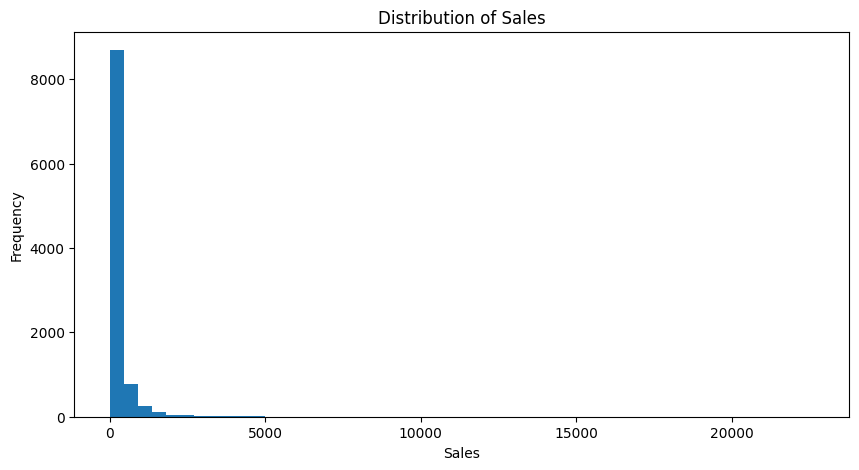

In [81]:
#Visualize distributions using Histograms
plt.figure(figsize=(10, 5))
plt.hist(df2['Sales'], bins=50)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

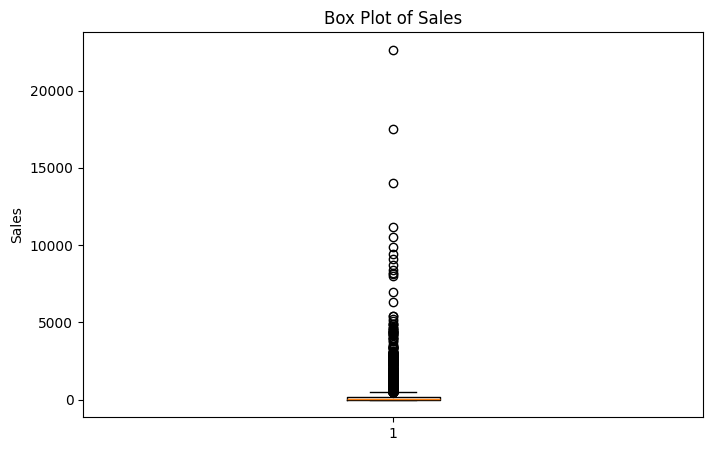

In [82]:
# Visualize distributions using boxplot
plt.figure(figsize=(8, 5))
plt.boxplot(df2['Sales'])
plt.title('Box Plot of Sales')
plt.ylabel('Sales')
plt.show()

In [83]:
## Detect and flag outliers in selected numerical columns using IQR
numeric_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

for col in numeric_columns:
  Q1=df2[col].quantile(0.25)
  Q3=df2[col].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR

  print("="*12 ,col,"="*12)
  print("Maximum:",df2[col].max())
  print("Lower Bound:", lower_bound)
  print("Upper Bound:",upper_bound)
  print("Outliers:",((df2[col]<lower_bound)|(df2[col]>upper_bound)).sum())
  #strategy : keep + flag
  df2[col + '_Outlier'] = df2[col].apply(
        lambda x: 'Outlier'
        if x < lower_bound or x > upper_bound
        else 'Normal'
    )

============ Sales ============
Maximum: 22638.48
Lower Bound: -271.71000000000004
Upper Bound: 498.93
Outliers: 1167
============ Quantity ============
Maximum: 14
Lower Bound: -2.5
Upper Bound: 9.5
Outliers: 170
============ Discount ============
Maximum: 0.8
Lower Bound: -0.30000000000000004
Upper Bound: 0.5
Outliers: 856
============ Profit ============
Maximum: 8399.976
Lower Bound: -39.7185
Upper Bound: 70.8135
Outliers: 1881


In [84]:
df2[df2["Discount"]>0.5]["Discount"].value_counts().sort_index()

,count
Discount,
0.6,138
0.7,418
0.8,300


In [85]:
df2[df2["Quantity"]>9.5]["Quantity"].value_counts().sort_index()

,count
Quantity,
10,57
11,34
12,23
13,27
14,29


## Categorical Encoding

In [86]:
# One Hot Encoding
df2=pd.get_dummies(df2,columns=["Sub-Category",'Category','Region','Segment'],dtype=int)

In [87]:
print(df2.columns)

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Country', 'City', 'State', 'Postal Code',
       'Product ID', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Sales_Outlier', 'Quantity_Outlier', 'Discount_Outlier',
       'Profit_Outlier', 'Sub-Category_Accessories', 'Sub-Category_Appliances',
       'Sub-Category_Art', 'Sub-Category_Binders', 'Sub-Category_Bookcases',
       'Sub-Category_Chairs', 'Sub-Category_Copiers', 'Sub-Category_Envelopes',
       'Sub-Category_Fasteners', 'Sub-Category_Furnishings',
       'Sub-Category_Labels', 'Sub-Category_Machines', 'Sub-Category_Paper',
       'Sub-Category_Phones', 'Sub-Category_Storage', 'Sub-Category_Supplies',
       'Sub-Category_Tables', 'Category_Furniture', 'Category_Office Supplies',
       'Category_Technology', 'Region_Central', 'Region_East', 'Region_South',
       'Region_West', 'Segment_Consumer', 'Segment_Corporate',
       'Segment_Home Office'],
      dt

In [88]:
df2.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Country,City,State,Postal Code,...,Category_Furniture,Category_Office Supplies,Category_Technology,Region_Central,Region_East,Region_South,Region_West,Segment_Consumer,Segment_Corporate,Segment_Home Office
Row ID,,,,,,,,,,,,,,,,,,,,,
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,United States,Henderson,Kentucky,42420,...,1,0,0,0,0,1,0,1,0,0
2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,United States,Henderson,Kentucky,42420,...,1,0,0,0,0,1,0,1,0,0
3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,United States,Los Angeles,California,90036,...,0,1,0,0,0,0,1,0,1,0
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,United States,Fort Lauderdale,Florida,33311,...,1,0,0,0,0,1,0,1,0,0
5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,United States,Fort Lauderdale,Florida,33311,...,0,1,0,0,0,1,0,1,0,0


In [89]:
# Ordinal Encoding
ship_mode_mapping = {
    'Standard Class': 1,
    'Second Class': 2,
    'First Class': 3,
    'Same Day': 4
}

df2['Ship Mode'] = df2['Ship Mode'].map(ship_mode_mapping)

In [90]:
df2.head()


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Country,City,State,Postal Code,...,Category_Furniture,Category_Office Supplies,Category_Technology,Region_Central,Region_East,Region_South,Region_West,Segment_Consumer,Segment_Corporate,Segment_Home Office
Row ID,,,,,,,,,,,,,,,,,,,,,
1,CA-2016-152156,2016-11-08,2016-11-11,2,CG-12520,Claire Gute,United States,Henderson,Kentucky,42420,...,1,0,0,0,0,1,0,1,0,0
2,CA-2016-152156,2016-11-08,2016-11-11,2,CG-12520,Claire Gute,United States,Henderson,Kentucky,42420,...,1,0,0,0,0,1,0,1,0,0
3,CA-2016-138688,2016-06-12,2016-06-16,2,DV-13045,Darrin Van Huff,United States,Los Angeles,California,90036,...,0,1,0,0,0,0,1,0,1,0
4,US-2015-108966,2015-10-11,2015-10-18,1,SO-20335,Sean O'Donnell,United States,Fort Lauderdale,Florida,33311,...,1,0,0,0,0,1,0,1,0,0
5,US-2015-108966,2015-10-11,2015-10-18,1,SO-20335,Sean O'Donnell,United States,Fort Lauderdale,Florida,33311,...,0,1,0,0,0,1,0,1,0,0


In [91]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9993 entries, 1 to 9994
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order ID                  9993 non-null   object        
 1   Order Date                9993 non-null   datetime64[ns]
 2   Ship Date                 9993 non-null   datetime64[ns]
 3   Ship Mode                 9993 non-null   int64         
 4   Customer ID               9993 non-null   object        
 5   Customer Name             9993 non-null   object        
 6   Country                   9993 non-null   object        
 7   City                      9993 non-null   object        
 8   State                     9993 non-null   object        
 9   Postal Code               9993 non-null   object        
 10  Product ID                9993 non-null   object        
 11  Product Name              9993 non-null   object        
 12  Sales                    

## Feature Scaling

In [92]:
scaling_columns = ['Sales', 'Quantity', 'Discount', 'Profit']
X = df2[scaling_columns]

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

In [93]:
#Standard scaler
standard_scaler = StandardScaler()

X_train_standard = standard_scaler.fit_transform(X_train)

X_test_standard = standard_scaler.transform(X_test)

In [94]:
# MinMaxscaler
min_max_scaler = MinMaxScaler()

X_train_minmax = min_max_scaler.fit_transform(X_train)

X_test_minmax = min_max_scaler.transform(X_test)

In [95]:
X_train_standard_df = pd.DataFrame(
    X_train_standard,
    columns=scaling_columns,
    index=X_train.index
)

X_train_minmax_df = pd.DataFrame(
    X_train_minmax,
    columns=scaling_columns,
    index=X_train.index
)

In [96]:
print("StandardScaler:")
print(X_train_standard_df.head())

print("MinMaxScaler:")
print(X_train_minmax_df.head())

StandardScaler:
           Sales  Quantity  Discount    Profit
Row ID                                        
4100   -0.365245 -0.804858 -0.758513 -0.107925
3537   -0.317294 -0.355271 -0.758513 -0.135524
3499   -0.361278  0.543902  0.214028 -0.113096
5854   -0.370937 -0.804858 -0.758513 -0.115875
169    -0.332259  0.993488  0.214028 -0.106361
MinMaxScaler:
           Sales  Quantity  Discount    Profit
Row ID                                        
4100    0.000714  0.076923      0.00  0.306429
3537    0.002303  0.153846      0.00  0.305928
3499    0.000846  0.307692      0.25  0.306335
5854    0.000526  0.076923      0.00  0.306285
169     0.001807  0.384615      0.25  0.306457


In [97]:
#comparison
print("StandardScaler Statistics:")
print(X_train_standard_df.describe())

print("MinMaxScaler Statistics:")
print(X_train_minmax_df.describe())

StandardScaler Statistics:
              Sales      Quantity      Discount        Profit
count  7.994000e+03  7.994000e+03  7.994000e+03  7.994000e+03
mean  -2.844304e-17  7.021876e-17 -1.435485e-16  7.332972e-18
std    1.000063e+00  1.000063e+00  1.000063e+00  1.000063e+00
min   -3.867986e-01 -1.254444e+00 -7.585129e-01 -1.698953e+01
25%   -3.576556e-01 -8.048577e-01 -7.585129e-01 -1.296076e-01
50%   -2.923841e-01 -3.552712e-01  2.140284e-01 -9.790417e-02
75%   -2.539902e-02  5.439018e-01  2.140284e-01 -2.175737e-03
max    2.979711e+01  4.590180e+00  3.131652e+00  3.810190e+01
MinMaxScaler Statistics:
             Sales     Quantity     Discount       Profit
count  7994.000000  7994.000000  7994.000000  7994.000000
mean      0.012815     0.214632     0.194982     0.308388
std       0.033132     0.171108     0.257075     0.018153
min       0.000000     0.000000     0.000000     0.000000
25%       0.000966     0.076923     0.000000     0.306035
50%       0.003128     0.153846     0.2500

# Final Data Quality Validation

In [98]:

#Recheck missing values
print("Missing Values:")
print(df2.isnull().sum())

Missing Values:
Order ID                    0
Order Date                  0
Ship Date                   0
Ship Mode                   0
Customer ID                 0
Customer Name               0
Country                     0
City                        0
State                       0
Postal Code                 0
Product ID                  0
Product Name                0
Sales                       0
Quantity                    0
Discount                    0
Profit                      0
Sales_Outlier               0
Quantity_Outlier            0
Discount_Outlier            0
Profit_Outlier              0
Sub-Category_Accessories    0
Sub-Category_Appliances     0
Sub-Category_Art            0
Sub-Category_Binders        0
Sub-Category_Bookcases      0
Sub-Category_Chairs         0
Sub-Category_Copiers        0
Sub-Category_Envelopes      0
Sub-Category_Fasteners      0
Sub-Category_Furnishings    0
Sub-Category_Labels         0
Sub-Category_Machines       0
Sub-Category_Paper      

In [99]:
#Recheck duplicated values
print("Duplicated Values:")
df2.duplicated().sum()

Duplicated Values:


np.int64(0)

In [100]:
#Recheck Invalid Values
print("Invalid Sales:", (df2['Sales'] <= 0).sum())

print("Invalid Quantity:", (df2['Quantity'] <= 0).sum())

print("Invalid Discount:",
      ((df2['Discount'] < 0) | (df2['Discount'] > 1)).sum())

print("Invalid Dates:",
      (df2['Ship Date'] < df2['Order Date']).sum())

Invalid Sales: 0
Invalid Quantity: 0
Invalid Discount: 0
Invalid Dates: 0


In [103]:
#Compare Data Quality Before and After Cleaning
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df2.shape)

print("Original Missing Values:", df.isnull().sum().sum())
print("Cleaned Missing Values:", df2.isnull().sum().sum())

print("Original Duplicates:", df.duplicated().sum())
print("Cleaned Duplicates:", df2.duplicated().sum())

Original Dataset Shape: (9994, 21)
Cleaned Dataset Shape: (9993, 47)
Original Missing Values: 0
Cleaned Missing Values: 0
Original Duplicates: 0
Cleaned Duplicates: 0


### Upload data_cleaned.csv

In [104]:
df2.to_csv("cleaned_data.csv",index=False)

In [105]:
from google.colab import files
files.download("cleaned_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>